[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch07-simple_workbook.ipynb)

# Greedy, beam and the nucleus on the novel

Count which word follows which in Pride and Prejudice, and every word gives a
distribution over the next one. What does greedy decoding write from `i`?
Does a wider beam always find a more probable continuation of `elizabeth`?
How many words does the nucleus keep after `mr`, and after `the`?

In [1]:
#@title Setup: run this cell first
import functools
import math
import os
import re
import urllib.request
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

MIRROR_REF = "main"
TEXT_URL = f"https://raw.githubusercontent.com/josterri/predicting-the-next-words-notebooks/{MIRROR_REF}/data/pride_and_prejudice.txt"


def load_novel():
    """Pride and Prejudice as lowercase word tokens, one list per chapter."""
    if os.environ.get("PNW_TEXT"):
        text = open(os.environ["PNW_TEXT"], encoding="utf-8").read()
    else:
        try:
            text = urllib.request.urlopen(TEXT_URL).read().decode("utf-8")
        except OSError as e:
            raise RuntimeError(f"The text did not download from {TEXT_URL}: {e}. "
                               "Run this cell again; every cell below needs it.") from None
    chapters = re.split(r"(?m)^CHAPTER [IVXLC]+\.$", text)[1:]
    return [re.findall(r"[a-z]+(?:'[a-z]+)*", c.lower().replace("’", "'")) for c in chapters]


plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


CHAPTERS = load_novel()
NEXT = defaultdict(Counter)  # NEXT[a][b]: how often b follows a inside one chapter
for chapter in CHAPTERS:
    for a, b in zip(chapter, chapter[1:]):
        NEXT[a][b] += 1
FIRST = CHAPTERS[0][:23]  # the novel's first sentence


@functools.lru_cache(maxsize=None)
def dist(a):  # the words after a, the most probable first, with their probabilities
    after = NEXT.get(a, {})
    return tuple(sorted(((w, k / sum(after.values())) for w, k in after.items()), key=lambda t: (-t[1], t[0])))


def word(name, w):  # a word typed in a cell, one the novel follows with another word
    q = w.strip().lower() if isinstance(w, str) else w
    if not NEXT.get(q):
        raise Refused(f"{name} is {w!r}: {name} takes a word of the novel, such as elizabeth.")
    return q


def whole(name, x, lo, hi):  # a whole number typed in a cell
    if type(x) is not int or not lo <= x <= hi:
        raise Refused(f"{name} is {x!r}: {name} takes a whole number from {lo} to {hi}.")
    return x


def search(start, width, length):  # beam search by summed log-probability; width 1 is greedy decoding
    hyps = [((start,), 0.0)]
    for _ in range(length):  # a sequence whose last word has no follower is kept as it stands
        ext = [(h + (w,), s + math.log(p)) for h, s in hyps for w, p in dist(h[-1])] + [x for x in hyps if not dist(x[0][-1])]
        hyps = sorted(ext, key=lambda t: (-t[1], t[0]))[:width]
    return hyps[0]


def bars(title, labels, values, xlabel):  # one chart of labelled horizontal bars
    fig, ax = plt.subplots(figsize=(6, 0.32 * len(values) + 1.2), layout="constrained")
    b = ax.barh(range(len(values)), values, tick_label=labels, color="C0")
    ax.bar_label(b, fmt="%.3f", padding=2, fontsize=8)
    lo, hi = min(0, *values), max(0, *values)
    span = (hi - lo) or 1  # all bars at 0 still get an axis
    ax.set(title=title, xlabel=xlabel, xlim=(lo - 0.35 * span if lo < 0 else 0, hi + 0.3 * span if hi > 0 else int(lo == 0)),
           ylim=(len(values) - 0.5, -0.5))
    plt.show()


# Step 1: greedy decoding, the most probable next word at every step.
def greedy(start, length):
    s, n = word("START", start), whole("LENGTH", length, 1, 30)
    h = search(s, 1, n)[0]
    print(" ".join(h))
    bars(f"greedy decoding from {s}: the probability of each word", [f"{i} {w}" for i, w in enumerate(h[1:], 1)],
         [dict(dist(a))[b] for a, b in zip(h, h[1:])], "probability")


# Step 2: the best six-word continuation at several beam widths.
def beams(start, widths):
    s = word("START", start)
    if not (isinstance(widths, (list, tuple)) and widths and all(type(b) is int and 1 <= b <= 20 for b in widths)):
        raise Refused(f"WIDTHS is {widths!r}: WIDTHS takes a list of whole numbers from 1 to 20.")
    best = [search(s, b, 6) for b in widths]
    for b, (h, sc) in zip(widths, best):
        print(f"width {b}: {' '.join(h)}, summed log-probability {sc:.3f}")
    bars(f"the best six words after {s}", [f"{b}: {' '.join(h[1:])}" for b, (h, _) in zip(widths, best)],
         [sc for _, sc in best], "summed log-probability")


# Step 3: the nucleus after a word, after a temperature.
def nuclei(contexts, top_p, tau):
    if not (isinstance(contexts, (list, tuple)) and 1 <= len(contexts) <= 4):
        raise Refused(f"CONTEXTS is {contexts!r}: CONTEXTS takes a list of one to four words of the novel.")
    cs = [word("CONTEXTS", c) for c in contexts]
    if type(top_p) not in (int, float) or not 0.05 <= top_p <= 1 or type(tau) not in (int, float) or not 0.1 <= tau <= 5:
        raise Refused(f"TOP_P is {top_p!r} and TAU {tau!r}: TOP_P takes a number from 0.05 to 1, TAU one from 0.1 to 5.")
    fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
    for c in cs:
        p = np.array([v for _, v in dist(c)]) ** (1 / tau)
        run = np.round(np.cumsum(p / p.sum()), 9)
        size = int(np.argmax(run >= top_p)) + 1
        print(f"after {c}: {size:,} of {len(p):,} words in the nucleus; the first three " + ", ".join(w for w, _ in dist(c)[:3]))
        ax.plot(range(1, len(p) + 1), run, label=f"after {c}: {size:,} of {len(p):,}")
        ax.plot(size, run[size - 1], "o", color="C3")
    ax.axhline(top_p, ls="--", color="0.5")
    ax.set(xscale="log", xticks=[1, 10, 100, 1000], xticklabels=["1", "10", "100", "1,000"], ylim=(0, 1.05),
           xlabel="words, the most probable first", ylabel="running sum",
           title=f"running sums after TAU {tau}; dots: the nucleus at {top_p}")
    ax.legend(fontsize=8, loc="lower right")
    plt.show()


# Appendix: BLEU and ROUGE-1 of a continuation of the first sentence against the novel's own words.
def precision(cand, ref, n):  # matches, clipped by the reference's counts, and the candidate's n-grams
    c = Counter(tuple(cand[i:i + n]) for i in range(len(cand) - n + 1))
    r = Counter(tuple(ref[i:i + n]) for i in range(len(ref) - n + 1))
    return sum(min(v, r[g]) for g, v in c.items()), sum(c.values())


def continue_first(prompt_words, width):
    k, b = whole("PROMPT_WORDS", prompt_words, 1, 22), whole("WIDTH", width, 1, 10)
    ref, cand = FIRST[k:], list(search(FIRST[k - 1], b, len(FIRST) - k)[0][1:])
    rows = [precision(cand, ref, n) for n in range(1, 5)]
    logs = [math.log(m / t) for m, t in rows if t and m]
    bleu = 100 * min(1.0, math.exp(1 - len(ref) / len(cand))) * math.exp(sum(logs) / len(logs)) if logs else 0.0
    rouge = sum(min(v, Counter(cand)[w]) for w, v in Counter(ref).items()) / len(ref)
    print(f"prompt: {' '.join(FIRST[:k])}\nwidth {b}: {' '.join(cand)}\nnovel:   {' '.join(ref)}")
    print("; ".join(f"p{n} {m}/{t}" for n, (m, t) in enumerate(rows, 1)) + f"; BLEU {bleu:.1f}, zero orders dropped; ROUGE-1 {rouge:.3f}")
    bars(f"width {b} against the novel's {len(ref)} words", ["p1", "p2", "p3", "p4", "ROUGE-1"],
         [m / t if t else 0.0 for m, t in rows] + [rouge], "share")


display(Markdown(f"{len(CHAPTERS)} chapters, {sum(map(len, CHAPTERS)):,} words; {len(NEXT):,} different words have a "
                 "word after them inside a chapter."))

61 chapters, 122,174 words; 6,313 different words have a word after them inside a chapter.

## 1. Greedy decoding loops

Greedy decoding writes the novel's most probable next word and moves on.
Run the cell from `i`: where does the text start to repeat? Then set `START`
to `elizabeth` and to `mr`.

i am sure i am sure i am sure i am sure i


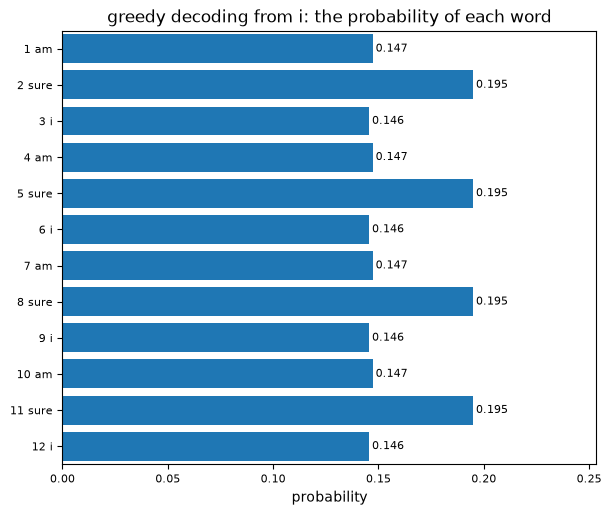

In [2]:
START, LENGTH = "i", 12
greedy(START, LENGTH)

### Solution

In [3]:
loop, eliz = search("i", 1, 12)[0], search("elizabeth", 1, 12)[0]
i = next(i for i, w in enumerate(eliz) if w in eliz[i + 1:])
period = eliz[i + 1:].index(eliz[i]) + 1
display(Markdown(f"From `i` greedy writes `{' '.join(loop)}`: after `sure` the most probable word is `i` again, at "
                 f"{dict(dist('sure'))['i']:.3f}, so the three words repeat. From `elizabeth` it writes `{' '.join(eliz)}`, "
                 f"and the {period} words `{' '.join(eliz[i:i + period])}` repeat."))

From `i` greedy writes `i am sure i am sure i am sure i am sure i`: after `sure` the most probable word is `i` again, at 0.146, so the three words repeat. From `elizabeth` it writes `elizabeth was not be so much as to be so much as to`, and the 5 words `be so much as to` repeat.

## 2. Beam search at several widths

Beam search keeps the `WIDTHS` best partial continuations at every step and
returns the six words with the highest summed log-probability. Run the cell:
does every wider beam find a more probable continuation? Then set `START` to
`she`.

width 1: elizabeth was not be so much as, summed log-probability -15.604
width 3: elizabeth had been so far from the, summed log-probability -13.776
width 5: elizabeth had been so much more than, summed log-probability -14.652
width 10: elizabeth i am sure i am sure, summed log-probability -13.114


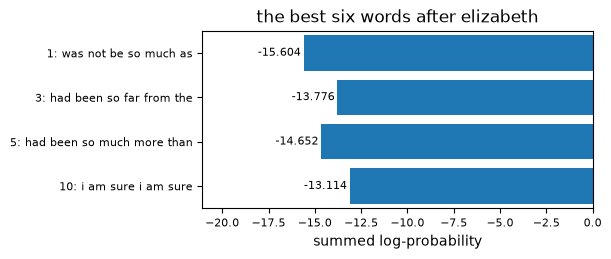

In [4]:
START, WIDTHS = "elizabeth", [1, 3, 5, 10]
beams(START, WIDTHS)

### Solution

In [5]:
s = {b: search("elizabeth", b, 6) for b in (1, 3, 5, 10)}
display(Markdown(f"Width 3 finds `{' '.join(s[3][0][1:])}` at {s[3][1]:.3f} against greedy's {s[1][1]:.3f}, and width 10 "
                 f"`{' '.join(s[10][0][1:])}` at {s[10][1]:.3f}. Width 5 returns {s[5][1]:.3f}, below width 3: at one step "
                 "the prefix width 3 kept fell out of width 5's five, behind extensions of hypotheses width 3 never kept."))

Width 3 finds `had been so far from the` at -13.776 against greedy's -15.604, and width 10 `i am sure i am sure` at -13.114. Width 5 returns -14.652, below width 3: at one step the prefix width 3 kept fell out of width 5's five, behind extensions of hypotheses width 3 never kept.

## 3. The nucleus after a word

The nucleus is the smallest set of words whose probabilities add up to at
least `TOP_P`. Run the cell: how many words follow `mr` in the nucleus, and
how many follow `the`? Then set `TAU` to `0.5` and to `2`.

after mr: 9 of 25 words in the nucleus; the first three darcy, collins, bingley
after the: 825 of 1,258 words in the nucleus; the first three whole, room, same


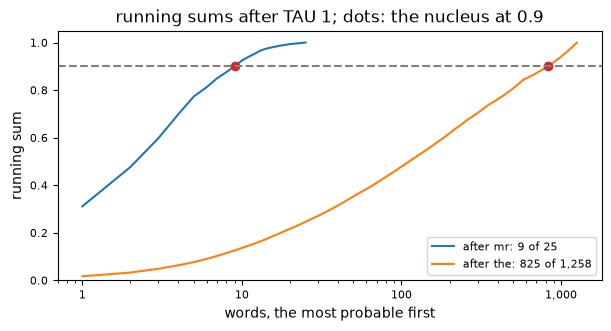

In [6]:
CONTEXTS, TOP_P, TAU = ["mr", "the"], 0.9, 1
nuclei(CONTEXTS, TOP_P, TAU)

### Solution

In [7]:
def size(c, tau):
    p = np.array([v for _, v in dist(c)]) ** (1 / tau)
    return int(np.argmax(np.round(np.cumsum(p / p.sum()), 9) >= 0.9)) + 1


display(Markdown(f"After `mr` the nucleus holds {size('mr', 1)} of {len(dist('mr'))} words, after `the` {size('the', 1)} of "
                 f"{len(dist('the')):,}: one setting of `TOP_P` keeps a handful of names or most of a vocabulary. At `TAU` 0.5 "
                 f"the two hold {size('mr', 0.5)} and {size('the', 0.5)}, and at 2 they hold {size('mr', 2)} and {size('the', 2):,}."))

After `mr` the nucleus holds 9 of 25 words, after `the` 825 of 1,258: one setting of `TOP_P` keeps a handful of names or most of a vocabulary. At `TAU` 0.5 the two hold 4 and 100, and at 2 they hold 17 and 1,063.

## Appendix. Scoring a continuation against the novel

The formulas behind the three steps and the scores:

probability of b after a = count of a followed by b / count of a followed by any word

score of a continuation = the sum of the logarithms of its word probabilities

BLEU = brevity penalty × the geometric mean of the clipped precisions p1 to p4, with brevity penalty = e to the power 1 − r/c for a candidate shorter than the reference

ROUGE-1 = reference words found in the candidate / reference words

The cell continues the first sentence of the novel from its first
`PROMPT_WORDS` words, by beam search of width `WIDTH`, and scores the
continuation against the novel's own words.

prompt: it is a truth
width 1: of the whole of the whole of the whole of the whole of the whole of the whole of
novel:   universally acknowledged that a single man in possession of a good fortune must be in want of a wife
p1 2/19; p2 0/18; p3 0/17; p4 0/16; BLEU 10.5, zero orders dropped; ROUGE-1 0.105


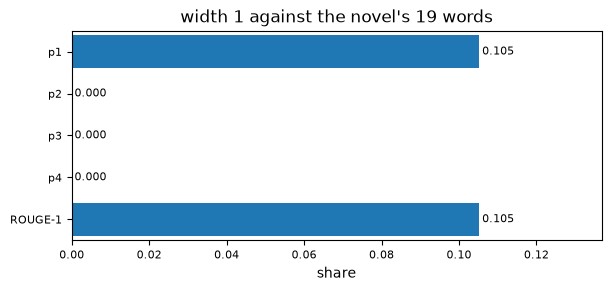

In [8]:
continue_first(4, 1)

**Exercise.** Set `WIDTH` to 3, then `PROMPT_WORDS` to 10, and rerun the
cell. Which continuation shares more words with the novel's?

prompt: it is a truth
width 1: of the whole of the whole of the whole of the whole of the whole of the whole of
novel:   universally acknowledged that a single man in possession of a good fortune must be in want of a wife
p1 2/19; p2 0/18; p3 0/17; p4 0/16; BLEU 10.5, zero orders dropped; ROUGE-1 0.105


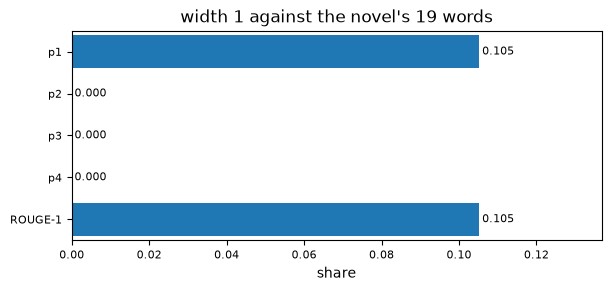

In [9]:
PROMPT_WORDS, WIDTH = 4, 1
continue_first(PROMPT_WORDS, WIDTH)

### Solution

In [10]:
def rouge(k, b):
    ref, cand = FIRST[k:], search(FIRST[k - 1], b, len(FIRST) - k)[0][1:]
    return sum(min(v, Counter(cand)[w]) for w, v in Counter(ref).items()) / len(ref)


display(Markdown(f"From 4 words ROUGE-1 is {rouge(4, 1):.3f} at width 1 and {rouge(4, 3):.3f} at width 3; from 10 words it is "
                 f"{rouge(10, 1):.3f} and {rouge(10, 3):.3f}. The bigram model sees only the prompt's last word, so a longer "
                 "prompt changes the continuation only through that word."))

From 4 words ROUGE-1 is 0.105 at width 1 and 0.105 at width 3; from 10 words it is 0.077 and 0.000. The bigram model sees only the prompt's last word, so a longer prompt changes the continuation only through that word.